# Lecture 7: Data Visualization

- This lecture covers plotting with Matplotlib and Seaborn. The data are the Fama-French five factors from Lecture 6.

## What We'll Cover

- **Ch 13 (Matplotlib):** the anatomy of a plot, the pyplot and object-oriented interfaces, line plots, customization, other plot types, subplots, saving figures, and style sheets.
- **Ch 14 (Seaborn):** distribution, relational, regression, and categorical plots, correlation heatmaps, multi-plot grids, and styling.

- Our running data is the **Fama-French 5 Factors** from Ken French's data library.

# Ch 13: Matplotlib

- **Matplotlib** is the foundational plotting library in Python.

- Most other Python plotting tools (including `pandas.plot()` and `seaborn`) are built on it.

- Once you know Matplotlib, you can customize any plot, including ones made by higher-level libraries.

## Importing Matplotlib

- The conventional alias for the plotting interface is `plt`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Loading Our Data

- We'll use the **Fama-French 5 Factors** dataset as our running example for plotting.

- These are monthly factor returns from Kenneth French's data library: `Mkt-RF` (market premium), `SMB` (size), `HML` (value), `RMW` (profitability), `CMA` (investment), and `RF` (risk-free rate).

- The cell below downloads the data fresh. It tries `pandas-datareader` first and falls back to a direct download if that fails.

In [ ]:
import io, zipfile, urllib.request

# Try pandas-datareader first (the cleanest path)
try:
    import pandas_datareader.data as web
    ff = web.DataReader('F-F_Research_Data_5_Factors_2x3',
                        'famafrench',
                        start='1990-01-01',
                        end='2023-12-31')
    ff5 = ff[0]
    ff5.index = ff5.index.to_timestamp()
    print(f"Loaded via pandas-datareader: {ff5.shape}")
except Exception as e:
    # Fallback: download the CSV zip directly from Ken French's website
    print(f"pandas-datareader failed ({type(e).__name__}); falling back to direct download.")
    url = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
           "ftp/F-F_Research_Data_5_Factors_2x3_CSV.zip")
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as r:
        zip_bytes = r.read()
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
        raw = z.open(z.namelist()[0]).read().decode('latin1')

    # The file has a text header; monthly data starts after a blank-line break.
    # Find the first line that begins with a 6-digit YYYYMM and parse from there.
    lines = raw.splitlines()
    start = next(i for i, ln in enumerate(lines)
                 if len(ln) >= 6 and ln[:6].isdigit())
    end = next((i for i in range(start, len(lines))
                if not (len(lines[i]) >= 6 and lines[i][:6].isdigit())),
               len(lines))
    monthly_csv = "Date,Mkt-RF,SMB,HML,RMW,CMA,RF\n" + "\n".join(lines[start:end])
    ff5 = pd.read_csv(io.StringIO(monthly_csv), index_col='Date')
    ff5.index = pd.to_datetime(ff5.index, format='%Y%m')
    print(f"Loaded via direct download: {ff5.shape}")

ff5.head()

Loaded via pandas-datareader: (408, 6)


,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,
1990-01-01,-7.80,-1.21,0.83,-1.12,1.40,0.57
1990-02-01,1.11,1.15,0.65,-0.04,-0.61,0.57
1990-03-01,1.83,1.59,-2.90,1.99,-0.94,0.64
1990-04-01,-3.36,-0.35,-2.57,1.78,-1.00,0.69
1990-05-01,8.44,-2.41,-3.89,1.68,-1.63,0.68


**Note on units:**
- Fama-French factor returns are stored in **percent** (a value of `1.5` means 1.5%).
- For plots like *cumulative returns*, we'll convert to decimal first (divide by 100).
- For *histograms of monthly returns*, percent is fine but we'll label axes accordingly.

## The Anatomy of a Plot

- Every Matplotlib plot has the same three-part structure:
  - A **Figure** is the whole image (the page).
  - One or more **Axes** sit inside the Figure (each Axes is one plot).
  - Each Axes has **Axis** objects (x-axis, y-axis) with ticks and labels.

## Two Interfaces

- The **pyplot interface** (`plt.plot()`, `plt.title()`, ...) is quick for simple plots. It operates on the "current" Axes implicitly.

- The **object-oriented interface** (`fig, ax = plt.subplots()`, `ax.plot()`, ...) gives you explicit handles and scales to complex layouts.

- We'll show both. Prefer the object-oriented style for anything beyond a one-liner.

## Your First Plot

### The pyplot Style

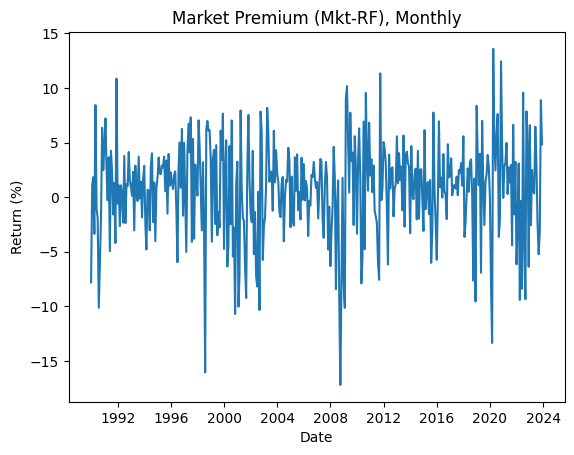

In [ ]:
# Quick line plot of one factor
plt.plot(ff5.index, ff5['Mkt-RF'])
plt.title('Market Premium (Mkt-RF), Monthly')
plt.xlabel('Date')
plt.ylabel('Return (%)')
plt.show()

### The Object-Oriented Style

- `plt.subplots()` creates a Figure and an Axes and returns both.

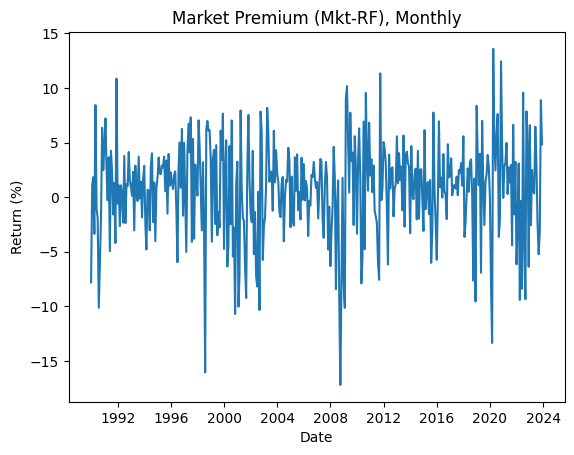

In [ ]:
fig, ax = plt.subplots()
ax.plot(ff5.index, ff5['Mkt-RF'])
ax.set_title('Market Premium (Mkt-RF), Monthly')
ax.set_xlabel('Date')
ax.set_ylabel('Return (%)')
plt.show()

- The plots look identical. We'll use the OO style from here on.

## Line Plots

### Multiple Lines on One Axes

- Call `ax.plot()` multiple times to overlay several series.

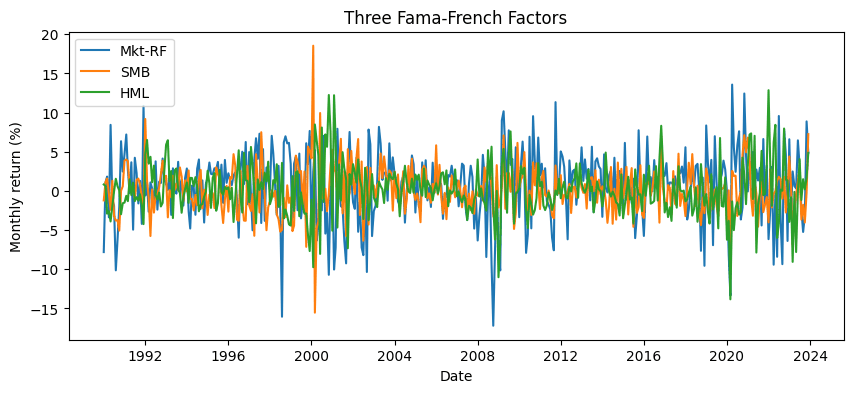

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ff5.index, ff5['Mkt-RF'], label='Mkt-RF')
ax.plot(ff5.index, ff5['SMB'],    label='SMB')
ax.plot(ff5.index, ff5['HML'],    label='HML')
ax.set_xlabel('Date')
ax.set_ylabel('Monthly return (%)')
ax.set_title('Three Fama-French Factors')
ax.legend()
plt.show()

### Cumulative Returns (Converting Percent to Decimal)

- Cumulative wealth `(1+r).cumprod()` requires returns in **decimal** form.

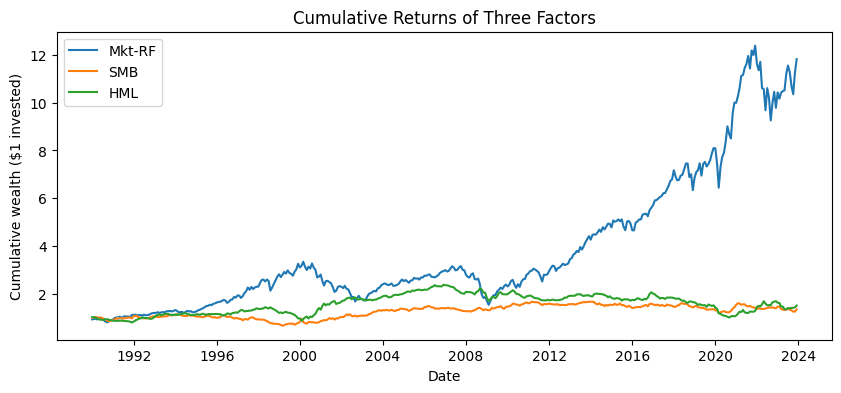

In [ ]:
# Convert from % to decimal, then compute cumulative wealth
cum_wealth = (1 + ff5[['Mkt-RF', 'SMB', 'HML']] / 100).cumprod()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cum_wealth.index, cum_wealth['Mkt-RF'], label='Mkt-RF')
ax.plot(cum_wealth.index, cum_wealth['SMB'],    label='SMB')
ax.plot(cum_wealth.index, cum_wealth['HML'],    label='HML')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative wealth ($1 invested)')
ax.set_title('Cumulative Returns of Three Factors')
ax.legend()
plt.show()

- `Mkt-RF` compounds to a much larger multiple than `SMB` or `HML` over 30+ years.

## Plot Customization

### Color, Line Style, Width, Markers

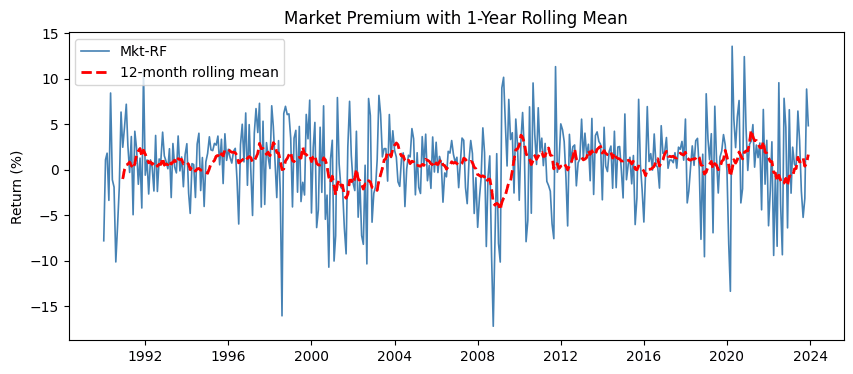

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ff5.index, ff5['Mkt-RF'],
        color='steelblue',
        linestyle='-',
        linewidth=1.2,
        label='Mkt-RF')
ax.plot(ff5.index, ff5['Mkt-RF'].rolling(12).mean(),
        color='red',
        linestyle='--',
        linewidth=2,
        label='12-month rolling mean')
ax.set_title('Market Premium with 1-Year Rolling Mean')
ax.set_ylabel('Return (%)')
ax.legend()
plt.show()

### Reference Lines: `axhline` and `axvline`

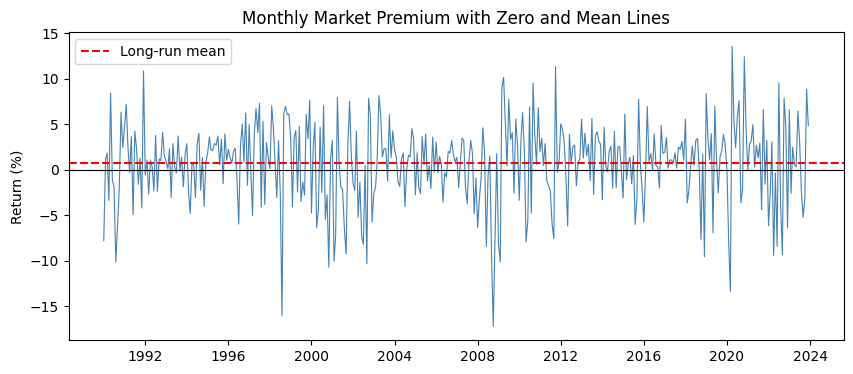

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ff5.index, ff5['Mkt-RF'], color='steelblue', linewidth=0.8)
ax.axhline(0, color='black', linewidth=0.8)              # zero line
ax.axhline(ff5['Mkt-RF'].mean(), color='red',
           linestyle='--', label='Long-run mean')
ax.set_title('Monthly Market Premium with Zero and Mean Lines')
ax.set_ylabel('Return (%)')
ax.legend()
plt.show()

### Grid

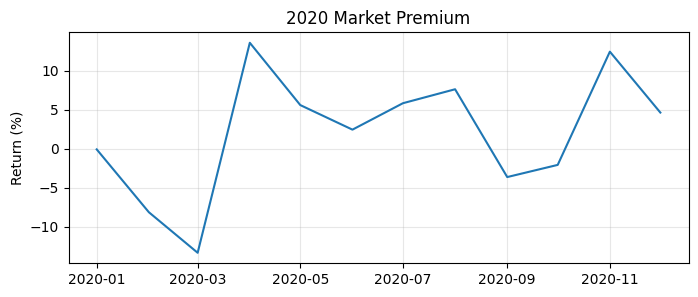

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ff5.loc['2020', 'Mkt-RF'])
ax.set_title('2020 Market Premium')
ax.set_ylabel('Return (%)')
ax.grid(True, alpha=0.3)
plt.show()

## Other Plot Types

### Histogram

- Use `ax.hist()` to see the distribution of values.

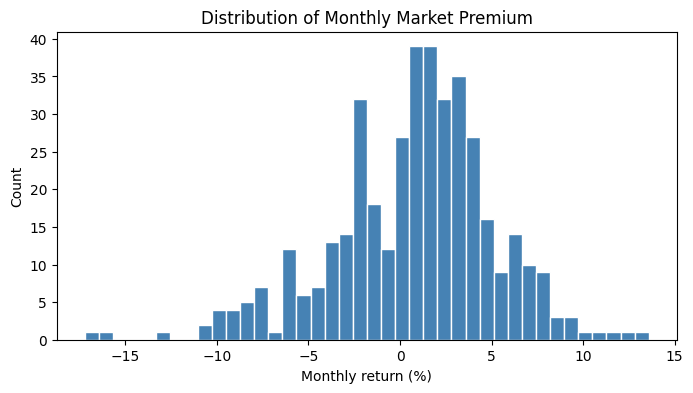

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ff5['Mkt-RF'], bins=40, color='steelblue', edgecolor='white')
ax.set_title('Distribution of Monthly Market Premium')
ax.set_xlabel('Monthly return (%)')
ax.set_ylabel('Count')
plt.show()

### Scatter Plot

- Use `ax.scatter()` to plot pairs of points.

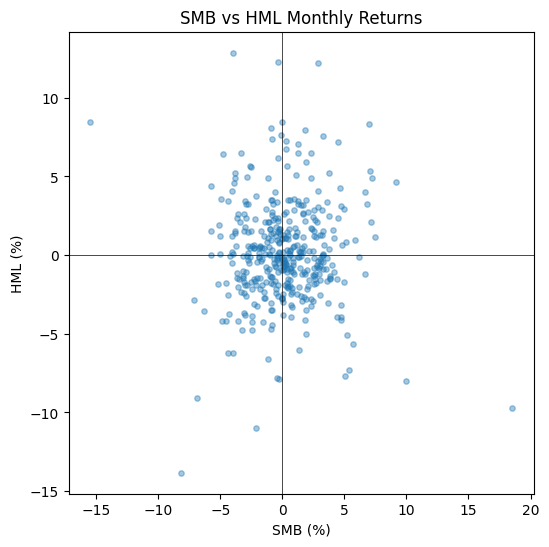

In [ ]:
# Do small-cap and value premia move together?
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(ff5['SMB'], ff5['HML'], alpha=0.4, s=15)
ax.set_xlabel('SMB (%)')
ax.set_ylabel('HML (%)')
ax.set_title('SMB vs HML Monthly Returns')
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
plt.show()

### Bar Chart

- Use `ax.bar()` for vertical bars (categorical x-axis).

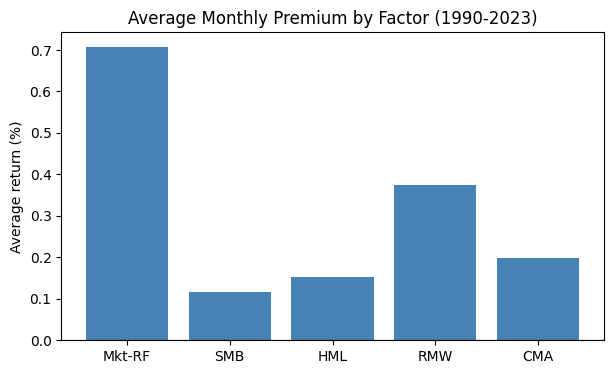

In [ ]:
# Average monthly return of each factor
mean_returns = ff5[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(mean_returns.index, mean_returns.values, color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Average Monthly Premium by Factor (1990-2023)')
ax.set_ylabel('Average return (%)')
plt.show()

### Boxplot

- A boxplot summarizes a distribution: median, quartiles, whiskers, and outliers.

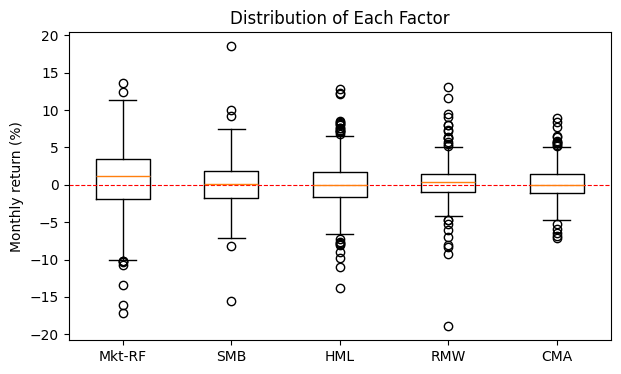

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([ff5['Mkt-RF'], ff5['SMB'], ff5['HML'], ff5['RMW'], ff5['CMA']],
           tick_labels=['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA'])
ax.axhline(0, color='red', linewidth=0.8, linestyle='--')
ax.set_ylabel('Monthly return (%)')
ax.set_title('Distribution of Each Factor')
plt.show()

## Subplots

- Use `plt.subplots(nrows, ncols)` to lay out multiple Axes in a grid.

- The returned `ax` is a NumPy array of Axes objects.

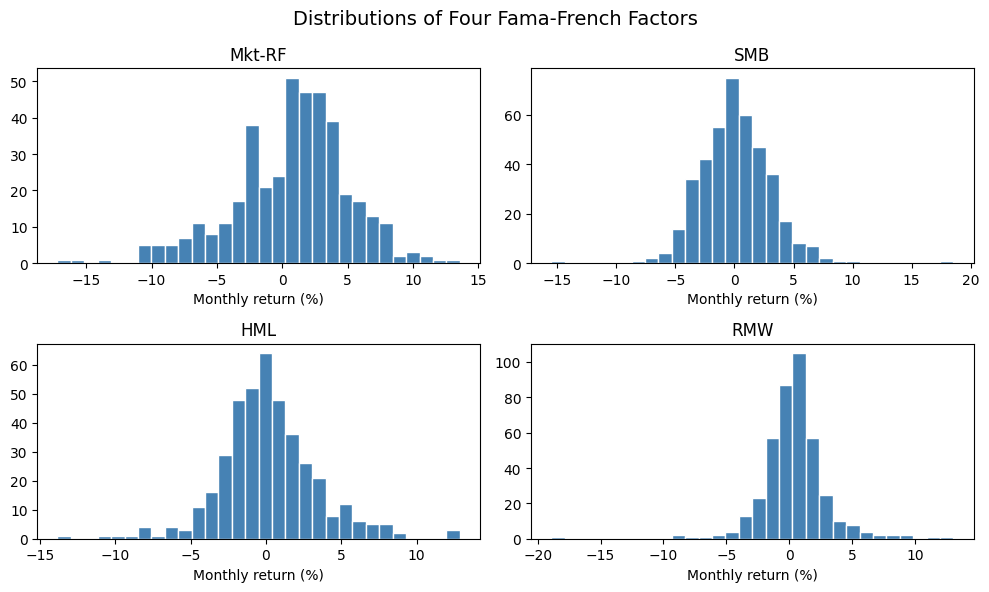

In [ ]:
factors = ['Mkt-RF', 'SMB', 'HML', 'RMW']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 6))

for ax, factor in zip(axes.flat, factors):
    ax.hist(ff5[factor], bins=30, color='steelblue', edgecolor='white')
    ax.set_title(factor)
    ax.set_xlabel('Monthly return (%)')

fig.suptitle('Distributions of Four Fama-French Factors', fontsize=14)
fig.tight_layout()
plt.show()

- `axes.flat` gives a flat iterator over all Axes regardless of grid shape.
- `fig.tight_layout()` automatically adjusts spacing so titles and labels don't overlap.

## Saving Figures

- Use `fig.savefig()` to write a figure to disk.

- The format is inferred from the file extension (`.png`, `.pdf`, `.svg`, ...).

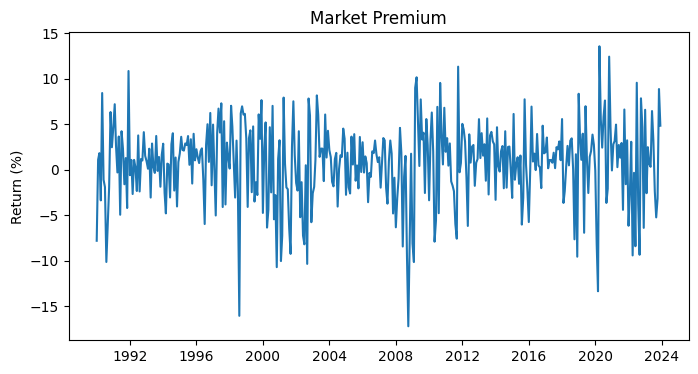

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ff5.index, ff5['Mkt-RF'])
ax.set_title('Market Premium')
ax.set_ylabel('Return (%)')

fig.savefig('mkt_rf.png', dpi=150, bbox_inches='tight')
plt.show()

- `dpi=150` controls resolution; `bbox_inches='tight'` trims whitespace.

## Style Sheets

- `plt.style.use(name)` applies a preset look-and-feel.

- Useful built-ins: `'ggplot'`, `'seaborn-v0_8'`, `'fivethirtyeight'`, `'classic'`.

In [ ]:
# See what styles are available
print(plt.style.available[:10])

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot']


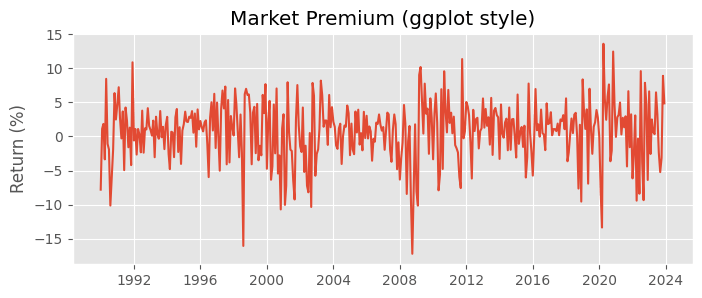

In [ ]:
# Apply a style for the rest of the notebook
plt.style.use('ggplot')

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ff5.index, ff5['Mkt-RF'])
ax.set_title('Market Premium (ggplot style)')
ax.set_ylabel('Return (%)')
plt.show()

In [ ]:
# Reset to default style before continuing
plt.style.use('default')

**Note: common pitfall**

- Forgetting `plt.show()` at the end of a cell still produces a plot in a notebook, but you'll also see noise like `<matplotlib.lines.Line2D at 0x...>`.

- Calling `plt.show()` (or assigning to `_`) keeps the output clean.

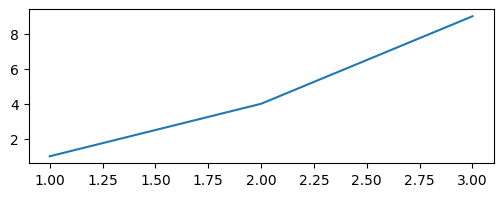

In [ ]:
# This works in a notebook but prints a stray repr line first.
fig, ax = plt.subplots(figsize=(6, 2))
ax.plot([1, 2, 3], [1, 4, 9])

## In-Class Exercise

**13-1. Line Plot:**
- Plot the `RF` (risk-free rate) series from `ff5` as a line plot using the object-oriented interface.
- Add a title `'Risk-Free Rate, Monthly'`, an x-label `'Date'`, and a y-label `'Rate (%)'`.

**13-2. Cumulative Wealth Comparison:**
- Compute the cumulative wealth of `Mkt-RF` and `RMW` (convert from percent to decimal first).
- Plot both on the same Axes with distinct colors and a legend.
- Set `figsize=(10, 4)` and give the plot an appropriate title.

**13-3. Histogram with Reference Line:**
- Plot a histogram of `HML` with 40 bins.
- Add a vertical dashed red line at the mean of `HML` using `ax.axvline()`.
- Label the axes appropriately.

**13-4. Side-by-Side Subplots:**
- Create a figure with 1 row and 2 columns using `plt.subplots(1, 2, figsize=(12, 4))`.
- On the left, plot `Mkt-RF` over time as a line.
- On the right, plot a histogram of `Mkt-RF`.
- Add appropriate titles to each subplot.

**13-5. Customized Scatter:**
- Make a scatter plot of `Mkt-RF` (x) vs `SMB` (y).
- Use `alpha=0.3` for transparency and `s=10` for point size.
- Add horizontal and vertical zero lines using `axhline(0)` and `axvline(0)`.
- Save the figure to `'mkt_vs_smb.png'` with `dpi=150`.

# Ch 14: Seaborn

- **Seaborn** is a high-level statistical visualization library built on top of Matplotlib.

- It produces attractive plots with less code, and is especially good at:
  - distribution plots
  - regression plots
  - categorical comparisons
  - correlation heatmaps

- Seaborn understands `pandas` DataFrames natively. You usually pass `data=df` and reference columns by name.

## Importing Seaborn

- The conventional alias for Seaborn is `sns`.

In [ ]:
import seaborn as sns
sns.set_theme(style='whitegrid')

- `sns.set_theme()` applies Seaborn's default styling to **all** subsequent Matplotlib plots.

- Common style choices: `'darkgrid'`, `'whitegrid'`, `'dark'`, `'white'`, `'ticks'`.

## Distribution Plots

### `histplot()`: Histograms with Density

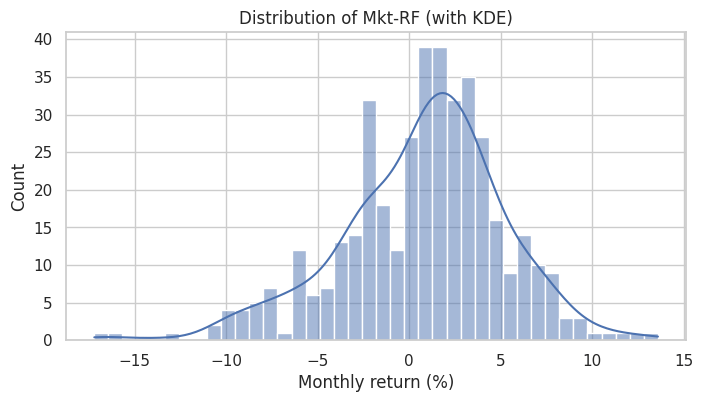

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=ff5, x='Mkt-RF', bins=40, kde=True, ax=ax)
ax.set_title('Distribution of Mkt-RF (with KDE)')
ax.set_xlabel('Monthly return (%)')
plt.show()

- `kde=True` overlays a **kernel density estimate** (a smoothed estimate of the distribution).

### `kdeplot()`: Compare Distributions

- Plot densities of multiple factors on the same Axes to compare their shapes.

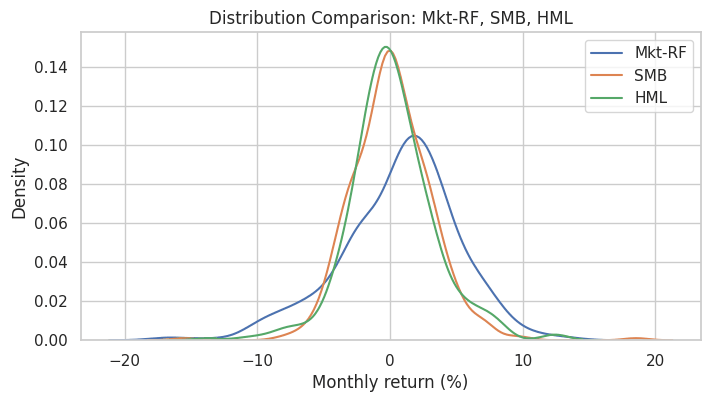

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for factor in ['Mkt-RF', 'SMB', 'HML']:
    sns.kdeplot(data=ff5, x=factor, label=factor, ax=ax)
ax.set_title('Distribution Comparison: Mkt-RF, SMB, HML')
ax.set_xlabel('Monthly return (%)')
ax.legend()
plt.show()

### `boxplot()` and `violinplot()`

- Box and violin plots compare distributions across **categories**.

- They work best with data in **long format**, so we `melt` the DataFrame first.

In [ ]:
ff5_long = ff5[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']].melt(
    var_name='factor', value_name='return'
)
ff5_long.head()

,factor,return
0,Mkt-RF,-7.80
1,Mkt-RF,1.11
2,Mkt-RF,1.83
3,Mkt-RF,-3.36
4,Mkt-RF,8.44


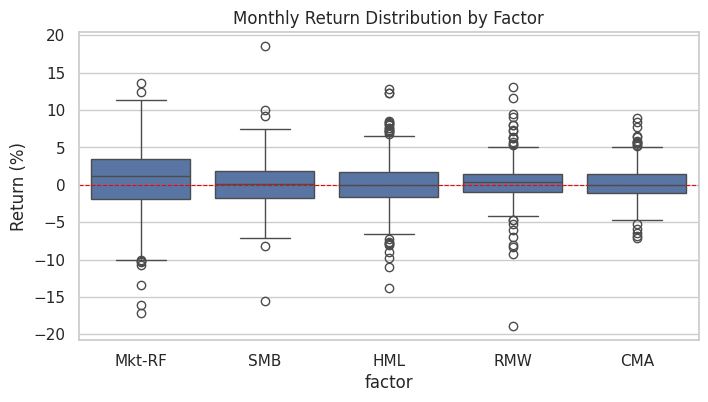

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=ff5_long, x='factor', y='return', ax=ax)
ax.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax.set_title('Monthly Return Distribution by Factor')
ax.set_ylabel('Return (%)')
plt.show()

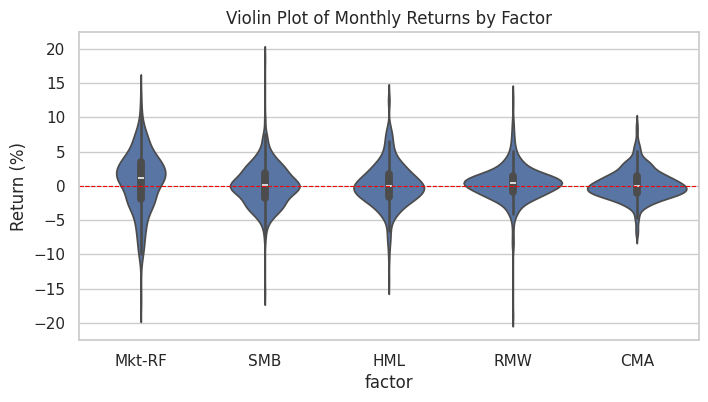

In [ ]:
# A violin plot shows the full KDE on each side
fig, ax = plt.subplots(figsize=(8, 4))
sns.violinplot(data=ff5_long, x='factor', y='return', ax=ax)
ax.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax.set_title('Violin Plot of Monthly Returns by Factor')
ax.set_ylabel('Return (%)')
plt.show()

## Relational Plots

### `scatterplot()` with a `hue`

- `hue` colors points by a categorical (or numeric) column.

In [ ]:
# Add a decade column for color-coding
ff5_demo = ff5.copy()
ff5_demo['decade'] = (ff5_demo.index.year // 10 * 10).astype(str) + 's'
ff5_demo.head()

,Mkt-RF,SMB,HML,RMW,CMA,RF,decade
Date,,,,,,,
1990-01-01,-7.80,-1.21,0.83,-1.12,1.40,0.57,1990s
1990-02-01,1.11,1.15,0.65,-0.04,-0.61,0.57,1990s
1990-03-01,1.83,1.59,-2.90,1.99,-0.94,0.64,1990s
1990-04-01,-3.36,-0.35,-2.57,1.78,-1.00,0.69,1990s
1990-05-01,8.44,-2.41,-3.89,1.68,-1.63,0.68,1990s


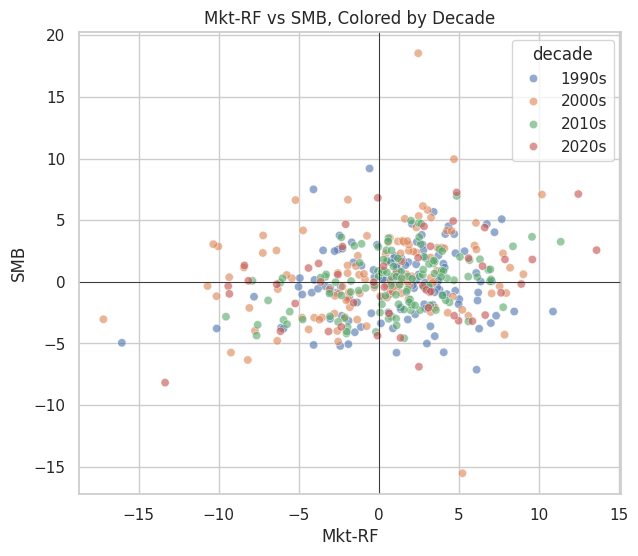

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=ff5_demo, x='Mkt-RF', y='SMB', hue='decade',
                alpha=0.6, ax=ax)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_title('Mkt-RF vs SMB, Colored by Decade')
plt.show()

### `lineplot()` with a confidence band

- `lineplot` is convenient when you have repeated observations and want a mean line with a confidence band.

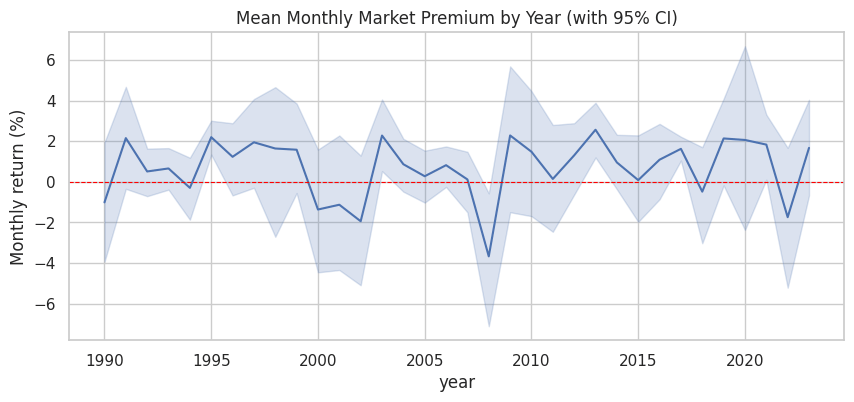

In [ ]:
# Mean monthly return by year, with confidence band
ff5_demo['year'] = ff5_demo.index.year

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=ff5_demo, x='year', y='Mkt-RF', ax=ax,
             errorbar=('ci', 95))
ax.axhline(0, color='red', linewidth=0.8, linestyle='--')
ax.set_title('Mean Monthly Market Premium by Year (with 95% CI)')
ax.set_ylabel('Monthly return (%)')
plt.show()

## Regression Plots

### `regplot()`: Scatter with Regression Line

- Adds a linear-regression fit and a confidence band on top of a scatter plot.

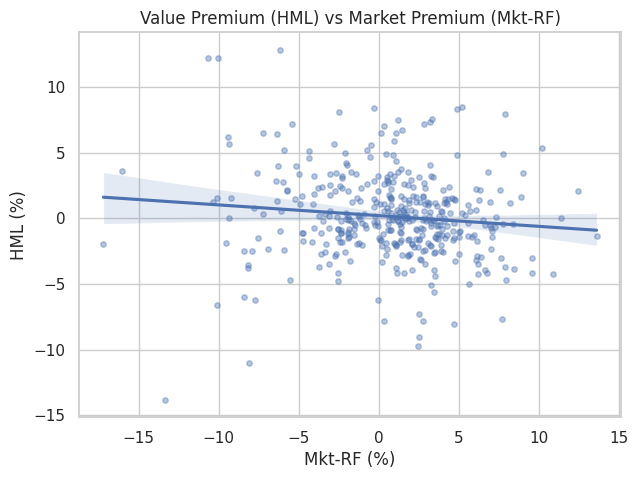

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=ff5, x='Mkt-RF', y='HML', scatter_kws={'alpha': 0.4, 's': 15}, ax=ax)
ax.set_title('Value Premium (HML) vs Market Premium (Mkt-RF)')
ax.set_xlabel('Mkt-RF (%)')
ax.set_ylabel('HML (%)')
plt.show()

- The shaded band is the 95% confidence interval for the regression line.

### `lmplot()`: Regression by Group

- `lmplot` fits a separate regression for each level of a categorical `hue` variable.

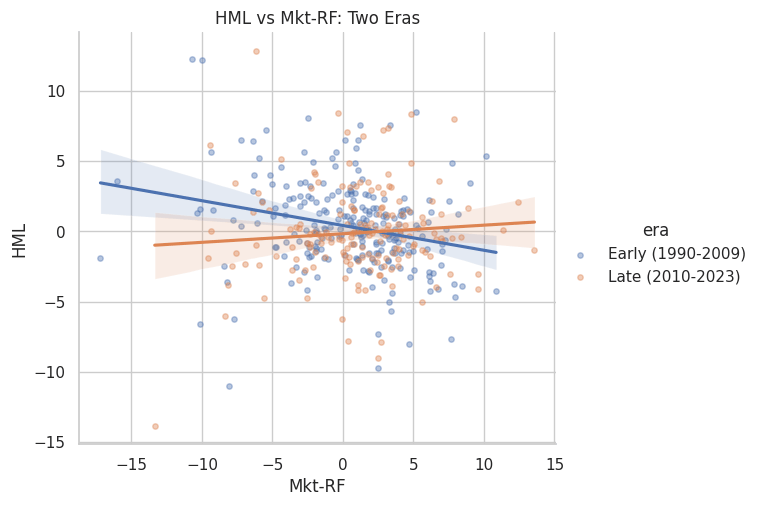

In [ ]:
# Split decades into 'early' (1990-2009) and 'late' (2010-2023)
ff5_demo['era'] = np.where(ff5_demo.index.year < 2010, 'Early (1990-2009)', 'Late (2010-2023)')

sns.lmplot(data=ff5_demo, x='Mkt-RF', y='HML', hue='era',
           height=5, aspect=1.2,
           scatter_kws={'alpha': 0.4, 's': 15})
plt.title('HML vs Mkt-RF: Two Eras')
plt.show()

- `lmplot` returns a `FacetGrid`, not an Axes, so we use `plt.title()` rather than `ax.set_title()`.

## Categorical Plots

### `barplot()`: Mean and Confidence Interval

- `barplot` computes the **mean** of `y` for each level of `x` by default, plus a confidence interval.

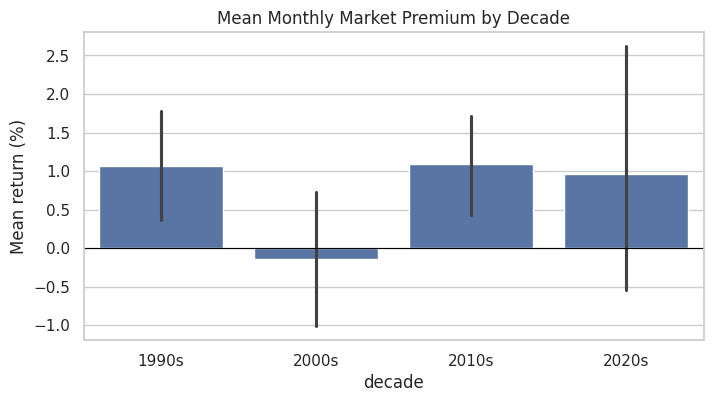

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=ff5_demo, x='decade', y='Mkt-RF', ax=ax)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Mean Monthly Market Premium by Decade')
ax.set_ylabel('Mean return (%)')
plt.show()

### `countplot()`: Frequency of Each Category

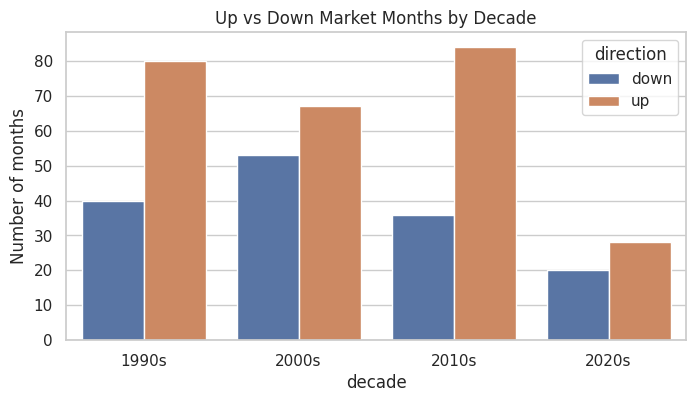

In [ ]:
# How many up vs down market months in each decade?
ff5_demo['direction'] = np.where(ff5_demo['Mkt-RF'] > 0, 'up', 'down')

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=ff5_demo, x='decade', hue='direction', ax=ax)
ax.set_title('Up vs Down Market Months by Decade')
ax.set_ylabel('Number of months')
plt.show()

## Matrix Plot: Correlation Heatmap

- A correlation **heatmap** shows how factors move together at a glance.

In [ ]:
corr = ff5[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']].corr()
corr

,Mkt-RF,SMB,HML,RMW,CMA
Mkt-RF,1.000000,0.231935,-0.111981,-0.314162,-0.329824
SMB,0.231935,1.000000,0.000160,-0.458621,-0.043114
HML,-0.111981,0.000160,1.000000,0.317990,0.660124
RMW,-0.314162,-0.458621,0.317990,1.000000,0.218510
CMA,-0.329824,-0.043114,0.660124,0.218510,1.000000


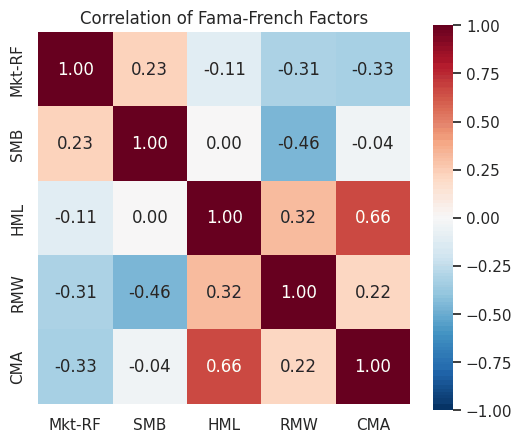

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,
            vmin=-1, vmax=1,
            square=True, ax=ax)
ax.set_title('Correlation of Fama-French Factors')
plt.show()

- `annot=True` writes the value in each cell; `fmt='.2f'` formats to two decimals.
- `cmap='RdBu_r'` is a diverging palette ideal for correlations: red = positive, blue = negative.
- `center=0` ensures the colormap is symmetric around zero.

## Multi-Plot Grids

### `pairplot()`: All-Pairs Scatter Matrix

- `pairplot` shows scatter plots for every pair of variables and histograms on the diagonal.

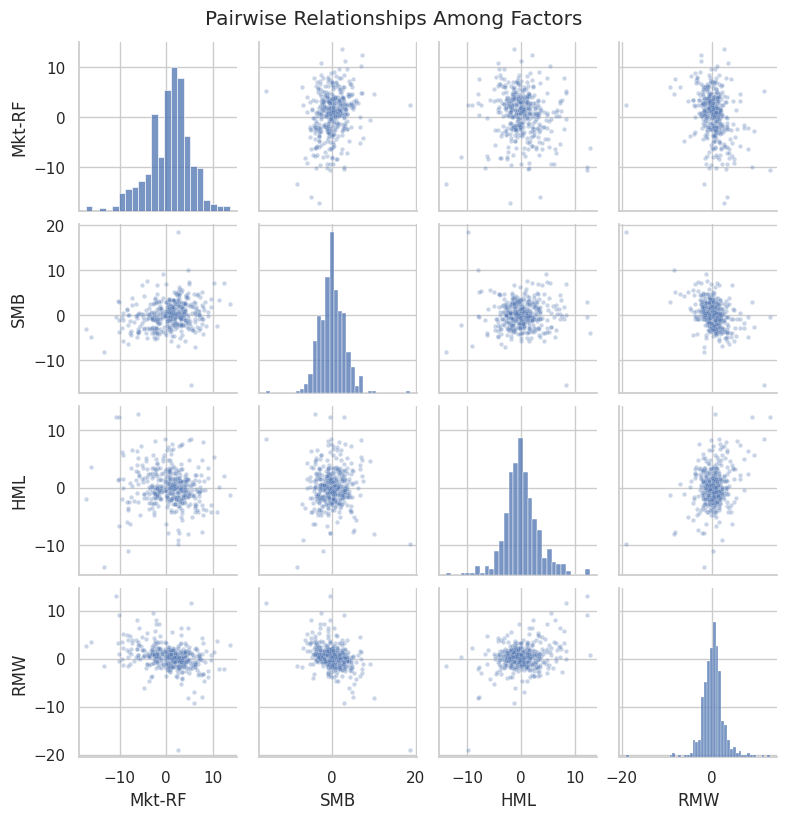

In [ ]:
sns.pairplot(ff5[['Mkt-RF', 'SMB', 'HML', 'RMW']],
             plot_kws={'alpha': 0.3, 's': 10},
             diag_kind='hist',
             height=2)
plt.suptitle('Pairwise Relationships Among Factors', y=1.02)
plt.show()

### Faceting with `catplot`

- `catplot` and `relplot` create grids of plots split by one or two categorical variables.

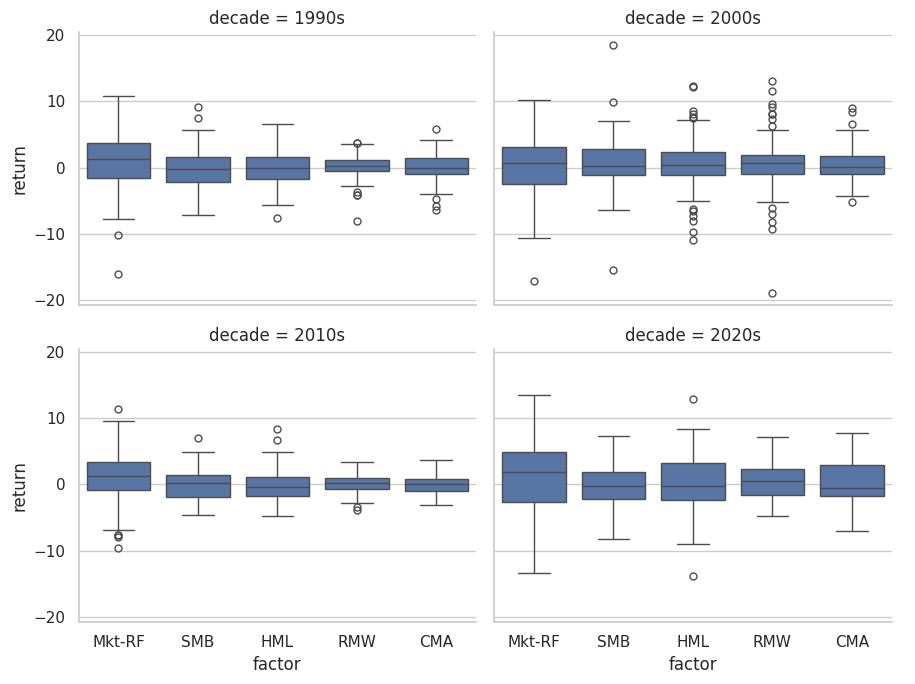

In [ ]:
# Build a long-format frame that carries decade through the melt
ff5_long_dec = (ff5_demo[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'decade']]
                .melt(id_vars='decade', var_name='factor', value_name='return'))

sns.catplot(data=ff5_long_dec, x='factor', y='return', col='decade',
            kind='box', col_wrap=2, height=3.5, aspect=1.3, sharey=True)
plt.show()

- The `col_wrap=2` argument wraps the facets into a 2-column grid.

- We melted with `id_vars='decade'` so `decade` survives the wide-to-long reshape.

## Styling and Palettes

### Themes

- `sns.set_theme(style=..., palette=...)` configures the global look.

deep
pastel
colorblind


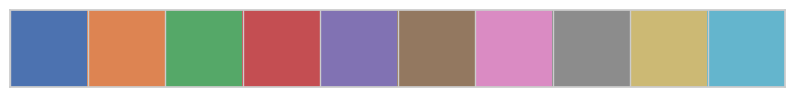

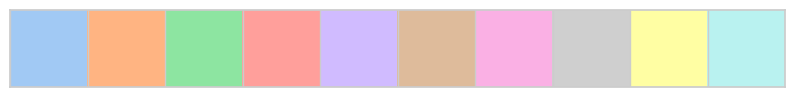

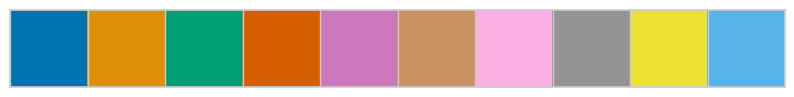

In [ ]:
# Show a few palette options
for palette in ['deep', 'pastel', 'colorblind']:
    print(palette)
    sns.palplot(sns.color_palette(palette))

### Per-Plot Palette

- You can also pass `palette=` to most Seaborn functions for one-off control.

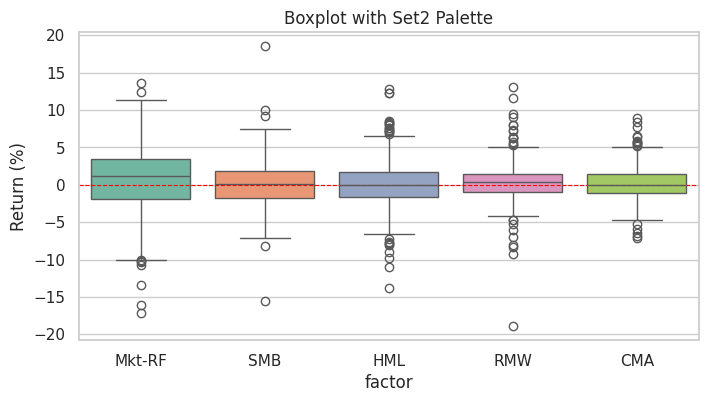

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=ff5_long, x='factor', y='return',
            hue='factor', palette='Set2', legend=False, ax=ax)
ax.axhline(0, color='red', linestyle='--', linewidth=0.8)
ax.set_title('Boxplot with Set2 Palette')
ax.set_ylabel('Return (%)')
plt.show()

## Matplotlib + Seaborn Together

- Seaborn returns Matplotlib Axes (for most functions), so you can mix the two freely.

- Use Seaborn for the statistical layer, then add Matplotlib annotations on top.

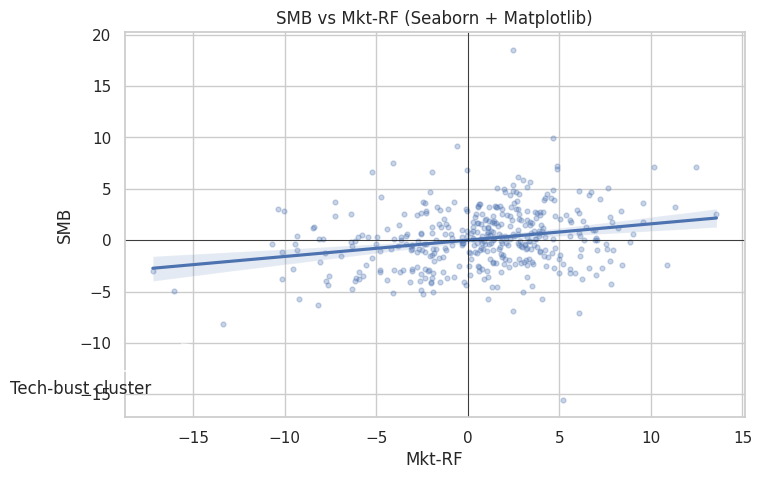

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

# Seaborn regression layer
sns.regplot(data=ff5, x='Mkt-RF', y='SMB',
            scatter_kws={'alpha': 0.3, 's': 12},
            ax=ax)

# Matplotlib annotations on the same Axes
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.annotate('Tech-bust cluster',
            xy=(-15, -10),
            xytext=(-25, -15),
            arrowprops={'arrowstyle': '->'})

ax.set_title('SMB vs Mkt-RF (Seaborn + Matplotlib)')
plt.show()

## In-Class Exercise

**14-1. Distribution Plot:**
- Use `sns.histplot()` with `kde=True` to plot the distribution of `RMW`.
- Set `bins=40` and give the plot a title and x-label.

**14-2. Comparing Distributions:**
- Use `sns.kdeplot()` to overlay the densities of `Mkt-RF`, `SMB`, and `HML` on a single Axes.
- Add a legend and an appropriate title.

**14-3. Regression Plot:**
- Use `sns.regplot()` to plot `Mkt-RF` (x) against `RMW` (y).
- Use semi-transparent markers (`alpha=0.4`) and a reasonable point size.
- What sign does the fitted line have? (Brief written answer in a markdown comment is fine.)

**14-4. Correlation Heatmap:**
- Compute the correlation matrix of the five factors `['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']`.
- Plot it with `sns.heatmap()` using `annot=True`, `cmap='RdBu_r'`, `center=0`, and `vmin=-1, vmax=1`.
- Which two factors are most negatively correlated?

**14-5. Categorical Comparison by Decade:**
- Create a `decade` column (e.g., `'1990s'`, `'2000s'`, ...) on a copy of `ff5`.
- Use `sns.barplot()` to show the mean monthly `Mkt-RF` by decade with confidence intervals.
- Add a zero-line with `ax.axhline(0)` for reference.

**14-6. Pairplot:**
- Use `sns.pairplot()` to plot all pairwise relationships among `Mkt-RF`, `SMB`, `HML`, and `CMA`.
- Use semi-transparent markers and histograms on the diagonal.